In [1]:

from pathlib import Path

DATASET_DIR = Path(
    "/kaggle/input/datasets/briscdataset/brisc2025/brisc2025"
)

CLASSIFICATION_DIR = DATASET_DIR / "classification_task"

classes = [
    "glioma",
    "meningioma",
    "pituitary",
    "no_tumor",
]

extensions = {".jpg", ".jpeg", ".png", ".bmp"}

print("Dataset exists:", DATASET_DIR.exists())
print("Classification folder exists:", CLASSIFICATION_DIR.exists())
print("\n" + "=" * 45)

for split in ["train", "test"]:
    print(f"\n{split.upper()} SET")
    total = 0

    for class_name in classes:
        folder = CLASSIFICATION_DIR / split / class_name

        if not folder.is_dir():
            print(f"{class_name}: FOLDER NOT FOUND")
            continue

        count = sum(
            1 for file in folder.iterdir()
            if file.is_file()
            and file.suffix.lower() in extensions
        )

        total += count
        print(f"{class_name:12s}: {count}")

    print(f"TOTAL: {total}")


Dataset exists: True
Classification folder exists: True


TRAIN SET
glioma      : 1147
meningioma  : 1329
pituitary   : 1457
no_tumor    : 1067
TOTAL: 5000

TEST SET
glioma      : 254
meningioma  : 306
pituitary   : 300
no_tumor    : 140
TOTAL: 1000


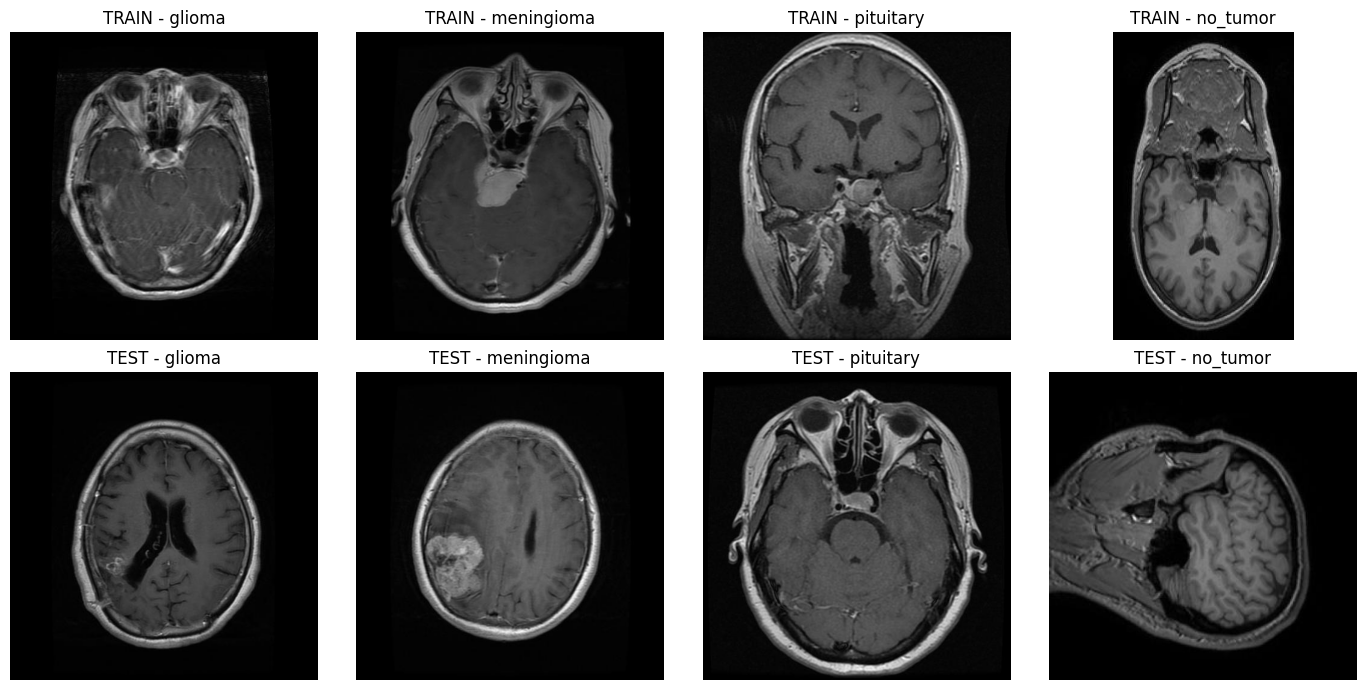

In [2]:

import matplotlib.pyplot as plt
from PIL import Image
import random

random.seed(42)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for row, split in enumerate(["train", "test"]):
    for col, class_name in enumerate(classes):
        folder = CLASSIFICATION_DIR / split / class_name

        image_files = [
            p for p in folder.iterdir()
            if p.is_file()
            and p.suffix.lower() in extensions
        ]

        image_path = random.choice(image_files)
        image = Image.open(image_path).convert("RGB")

        axes[row, col].imshow(image)
        axes[row, col].set_title(
            f"{split.upper()} - {class_name}"
        )
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()


In [2]:

from pathlib import Path
from PIL import Image
from collections import Counter
import random

# Dataset paths
DATASET_DIR = Path(
    "/kaggle/input/datasets/briscdataset/brisc2025/brisc2025"
)

CLASSIFICATION_DIR = DATASET_DIR / "classification_task"

classes = [
    "glioma",
    "meningioma",
    "pituitary",
    "no_tumor",
]

extensions = {".jpg", ".jpeg", ".png", ".bmp"}

random.seed(42)

print("Dataset exists:", DATASET_DIR.exists())
print("Classification folder exists:", CLASSIFICATION_DIR.exists())
print("=" * 45)

for class_name in classes:
    folder = CLASSIFICATION_DIR / "train" / class_name

    if not folder.is_dir():
        print(f"\nFolder not found: {folder}")
        continue

    image_files = [
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in extensions
    ]

    sample_paths = random.sample(
        image_files,
        min(20, len(image_files))
    )

    dimensions = Counter()
    errors = 0

    for path in sample_paths:
        try:
            with Image.open(path) as img:
                img.verify()

            with Image.open(path) as img:
                dimensions[img.size] += 1

        except Exception as e:
            errors += 1
            print(f"Could not read {path.name}: {e}")

    print(f"\nClass: {class_name}")
    print(f"Images sampled: {len(sample_paths)}")
    print(f"Reading errors: {errors}")

    for size, count in dimensions.most_common():
        print(f"  Dimensions {size}: {count} images")


Dataset exists: True
Classification folder exists: True

Class: glioma
Images sampled: 20
Reading errors: 0
  Dimensions (512, 512): 20 images

Class: meningioma
Images sampled: 20
Reading errors: 0
  Dimensions (512, 512): 19 images
  Dimensions (217, 232): 1 images

Class: pituitary
Images sampled: 20
Reading errors: 0
  Dimensions (512, 512): 20 images

Class: no_tumor
Images sampled: 20
Reading errors: 0
  Dimensions (369, 369): 8 images
  Dimensions (216, 369): 6 images
  Dimensions (512, 512): 5 images
  Dimensions (210, 369): 1 images


In [3]:

import tensorflow as tf
from pathlib import Path

SEED = 42
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

train_dir = CLASSIFICATION_DIR / "train"
test_dir = CLASSIFICATION_DIR / "test"

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    labels="inferred",
    label_mode="int",
    class_names=classes,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    labels="inferred",
    label_mode="int",
    class_names=classes,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    shuffle=True
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    labels="inferred",
    label_mode="int",
    class_names=classes,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    shuffle=False
)

print("\nClass order:", train_ds.class_names)
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())


Found 5000 files belonging to 4 classes.
Using 4000 files for training.
Found 5000 files belonging to 4 classes.
Using 1000 files for validation.


2026-10-23 10:21:06.536488: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Found 1000 files belonging to 4 classes.

Class order: ['glioma', 'meningioma', 'pituitary', 'no_tumor']
Image size: (224, 224)
Batch size: 32
Training batches: 125
Validation batches: 32
Test batches: 32


In [4]:

import tensorflow as tf

print("TensorFlow version:", tf.__version__)

print("\nAvailable GPU devices:")
gpus = tf.config.list_physical_devices("GPU")
print(gpus)

if gpus:
    print("\nGPU is available.")
else:
    print("\nGPU is NOT available. Training would use CPU.")


TensorFlow version: 2.20.0

Available GPU devices:
[]

GPU is NOT available. Training would use CPU.


In [1]:
import tensorflow as tf

print(tf.config.list_physical_devices("GPU"))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [2]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Reproducibility
tf.keras.utils.set_random_seed(42)

# CNN baseline model
model = keras.Sequential([
    layers.Input(shape=(224, 224, 3)),

    # Normalize pixel values from 0-255 to 0-1
    layers.Rescaling(1.0 / 255),

    # First convolution block
    layers.Conv2D(32, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    # Second convolution block
    layers.Conv2D(64, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    # Third convolution block
    layers.Conv2D(128, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    # Classification head
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(4, activation="softmax")
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


I0000 00:00:1792754712.425519      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792754712.428910      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,276 (430.77 KB)

 Trainable params: 110,276 (430.77 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:

import tensorflow as tf
from pathlib import Path

# Dataset paths
DATASET_DIR = Path(
    "/kaggle/input/datasets/briscdataset/brisc2025/brisc2025"
)
CLASSIFICATION_DIR = DATASET_DIR / "classification_task"

classes = [
    "glioma",
    "meningioma",
    "pituitary",
    "no_tumor",
]

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    CLASSIFICATION_DIR / "train",
    labels="inferred",
    label_mode="int",
    class_names=classes,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    CLASSIFICATION_DIR / "train",
    labels="inferred",
    label_mode="int",
    class_names=classes,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    CLASSIFICATION_DIR / "test",
    labels="inferred",
    label_mode="int",
    class_names=classes,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

print("\nDatasets successfully created.")
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())


Found 5000 files belonging to 4 classes.
Using 4000 files for training.
Found 5000 files belonging to 4 classes.
Using 1000 files for validation.
Found 1000 files belonging to 4 classes.

Datasets successfully created.
Training batches: 125
Validation batches: 32
Test batches: 32


Epoch 1/15
  3/125 ━━━━━━━━━━━━━━━━━━━━ 5s 47ms/step - accuracy: 0.3663 - loss: 1.3840 

I0000 00:00:1792755148.357177     145 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 641ms/step - accuracy: 0.3255 - loss: 1.3549
Epoch 1: val_loss improved from None to 1.13146, saving model to /kaggle/working/best_cnn.keras

Epoch 1: finished saving model to /kaggle/working/best_cnn.keras
125/125 ━━━━━━━━━━━━━━━━━━━━ 108s 807ms/step - accuracy: 0.3740 - loss: 1.3000 - val_accuracy: 0.4760 - val_loss: 1.1315
Epoch 2/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.5432 - loss: 1.0897
Epoch 2: val_loss improved from 1.13146 to 0.87828, saving model to /kaggle/working/best_cnn.keras

Epoch 2: finished saving model to /kaggle/working/best_cnn.keras
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 56ms/step - accuracy: 0.5600 - loss: 1.0600 - val_accuracy: 0.7050 - val_loss: 0.8783
Epoch 3/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.6472 - loss: 0.8987
Epoch 3: val_loss improved from 0.87828 to 0.70936, saving model to /kaggle/working/best_cnn.keras

Epoch 3: finished saving model to /kaggle/working/best_cnn.keras
125/125 ━━━━━━━━━━

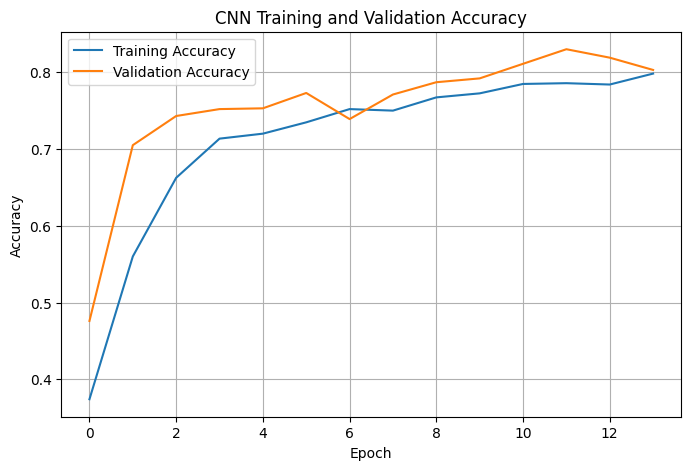

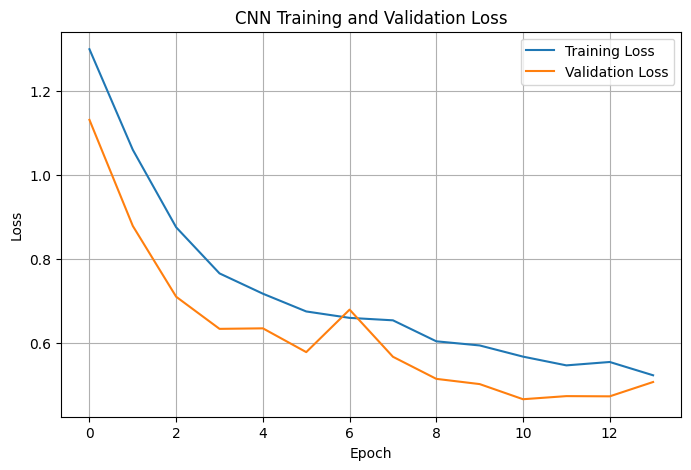

In [9]:

from pathlib import Path
import tensorflow as tf
import matplotlib.pyplot as plt

# Save the best model during training
checkpoint_path = "/kaggle/working/best_cnn.keras"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=checkpoint_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    )
]

# Train the baseline CNN
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)

print("\nTraining completed.")
print("Best model checkpoint:", checkpoint_path)

# Plot accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Plot loss
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


32/32 ━━━━━━━━━━━━━━━━━━━━ 22s 682ms/step - accuracy: 0.7560 - loss: 0.5841
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step

Test Loss: 0.5841
Test Accuracy: 0.7560

Classification Report:
              precision    recall  f1-score   support

      glioma     0.8854    0.5472    0.6764       254
  meningioma     0.6254    0.6765    0.6499       306
   pituitary     0.8304    0.9300    0.8774       300
    no_tumor     0.7443    0.9357    0.8291       140

    accuracy                         0.7560      1000
   macro avg     0.7714    0.7724    0.7582      1000
weighted avg     0.7696    0.7560    0.7500      1000



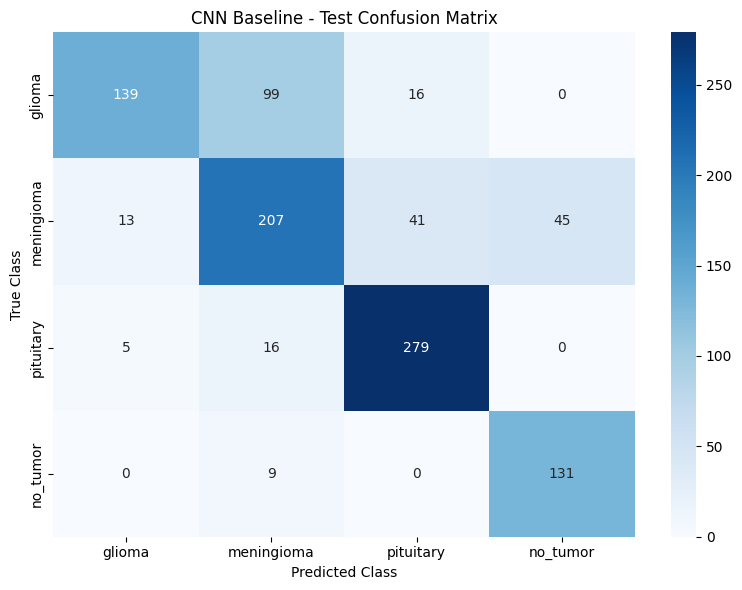

In [10]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Evaluate on the held-out test dataset
test_loss, test_accuracy = model.evaluate(
    test_ds,
    verbose=1
)

# Collect true labels
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# Predict class probabilities
y_prob = model.predict(test_ds, verbose=1)

# Convert probabilities to predicted class indices
y_pred = np.argmax(y_prob, axis=1)

# Calculate metrics
print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {accuracy_score(y_true, y_pred):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=classes,
    digits=4,
    zero_division=0
))

# Confusion Matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3]
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("CNN Baseline - Test Confusion Matrix")
plt.tight_layout()
plt.show()


In [11]:
import numpy as np
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print("Accuracy:", accuracy_score(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=classes,
    digits=4,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3]
))

32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step
Accuracy: 0.756

Classification Report:
              precision    recall  f1-score   support

      glioma     0.8854    0.5472    0.6764       254
  meningioma     0.6254    0.6765    0.6499       306
   pituitary     0.8304    0.9300    0.8774       300
    no_tumor     0.7443    0.9357    0.8291       140

    accuracy                         0.7560      1000
   macro avg     0.7714    0.7724    0.7582      1000
weighted avg     0.7696    0.7560    0.7500      1000


Confusion Matrix:
[[139  99  16   0]
 [ 13 207  41  45]
 [  5  16 279   0]
 [  0   9   0 131]]


In [2]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

base_model = keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

base_model.trainable = False

print("EfficientNetB0 loaded successfully.")
print("Number of layers:", len(base_model.layers))

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
EfficientNetB0 loaded successfully.
Number of layers: 238


In [3]:
from tensorflow import keras
from tensorflow.keras import layers

inputs = keras.Input(shape=(224, 224, 3))

# Extract features using the pretrained model
x = base_model(inputs, training=False)

# Convert feature maps into a feature vector
x = layers.GlobalAveragePooling2D()(x)

# Reduce overfitting
x = layers.Dropout(0.3)(x)

# Classify into four brain image classes
outputs = layers.Dense(4, activation="softmax")(x)

efficientnet_model = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="EfficientNetB0_Brain_Classification"
)

efficientnet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

efficientnet_model.summary()

Model: "EfficientNetB0_Brain_Classification"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,054,695 (15.47 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [6]:
print("Model exists:", "efficientnet_model" in globals())
print("Training data exists:", "train_ds" in globals())

Model exists: True
Training data exists: False


In [36]:
import tensorflow as tf
from pathlib import Path

CLASSIFICATION_DIR = Path(
    "/kaggle/input/datasets/briscdataset/brisc2025/brisc2025/classification_task"
)

classes = ["glioma", "meningioma", "pituitary", "no_tumor"]

train_ds = tf.keras.utils.image_dataset_from_directory(
    CLASSIFICATION_DIR / "train",
    labels="inferred",
    label_mode="int",
    class_names=classes,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(224, 224),
    batch_size=32,
    color_mode="rgb",
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    CLASSIFICATION_DIR / "train",
    labels="inferred",
    label_mode="int",
    class_names=classes,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(224, 224),
    batch_size=32,
    color_mode="rgb",
    shuffle=True
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    CLASSIFICATION_DIR / "test",
    labels="inferred",
    label_mode="int",
    class_names=classes,
    image_size=(224, 224),
    batch_size=32,
    color_mode="rgb",
    shuffle=False
)

print("All datasets are ready.")

Found 5000 files belonging to 4 classes.
Using 4000 files for training.
Found 5000 files belonging to 4 classes.
Using 1000 files for validation.
Found 1000 files belonging to 4 classes.
All datasets are ready.


In [37]:
import tensorflow as tf
import matplotlib.pyplot as plt

checkpoint_path = "/kaggle/working/best_efficientnetb0.keras"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=checkpoint_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    )
]

history_efficientnet = efficientnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)

print("\nEfficientNetB0 training completed.")
print("Best model checkpoint:", checkpoint_path)

Epoch 1/15


2026-10-23 21:07:50.714502: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-23 21:07:50.858079: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-23 21:07:51.226153: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-23 21:07:51.370578: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-23 21:07:51.512514: E external/local_xla/xla/stream_

125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 672ms/step - accuracy: 0.5622 - loss: 1.0373

2026-10-23 21:09:53.787995: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-23 21:09:53.926167: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-23 21:09:54.245210: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-23 21:09:54.387968: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-23 21:09:55.180280: E external/local_xla/xla/stream_


Epoch 1: val_loss improved from None to 0.44843, saving model to /kaggle/working/best_efficientnetb0.keras

Epoch 1: finished saving model to /kaggle/working/best_efficientnetb0.keras
125/125 ━━━━━━━━━━━━━━━━━━━━ 152s 969ms/step - accuracy: 0.6917 - loss: 0.7898 - val_accuracy: 0.8590 - val_loss: 0.4484
Epoch 2/15
124/125 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.8382 - loss: 0.4823
Epoch 2: val_loss improved from 0.44843 to 0.35648, saving model to /kaggle/working/best_efficientnetb0.keras

Epoch 2: finished saving model to /kaggle/working/best_efficientnetb0.keras
125/125 ━━━━━━━━━━━━━━━━━━━━ 6s 49ms/step - accuracy: 0.8360 - loss: 0.4725 - val_accuracy: 0.8780 - val_loss: 0.3565
Epoch 3/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.8687 - loss: 0.3922
Epoch 3: val_loss improved from 0.35648 to 0.30871, saving model to /kaggle/working/best_efficientnetb0.keras

Epoch 3: finished saving model to /kaggle/working/best_efficientnetb0.keras
125/125 ━━━━━━━━━━━━━━━━━━━━

In [39]:
import os

print("Working directory files:")
print(os.listdir("/kaggle/working"))

print("\nSearching for saved EfficientNet models...")

for root, dirs, files in os.walk("/kaggle/working"):
    for file in files:
        if "efficientnet" in file.lower() or file.endswith(".keras"):
            print(os.path.join(root, file))

Working directory files:
['.virtual_documents', 'best_efficientnetb0.keras']

Searching for saved EfficientNet models...
/kaggle/working/best_efficientnetb0.keras


In [40]:
print("efficientnet_model exists:",
      "efficientnet_model" in globals())

print("history_efficientnet exists:",
      "history_efficientnet" in globals())

print("test_ds exists:",
      "test_ds" in globals())

efficientnet_model exists: True
history_efficientnet exists: True
test_ds exists: True


In [41]:
import tensorflow as tf
from pathlib import Path

DATASET_DIR = Path(
    "/kaggle/input/datasets/briscdataset/brisc2025/brisc2025"
)
CLASSIFICATION_DIR = DATASET_DIR / "classification_task"

classes = ["glioma", "meningioma", "pituitary", "no_tumor"]
SEED = 42
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

train_dir = CLASSIFICATION_DIR / "train"
test_dir = CLASSIFICATION_DIR / "test"

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    labels="inferred",
    label_mode="int",
    class_names=classes,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    labels="inferred",
    label_mode="int",
    class_names=classes,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    shuffle=True
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    labels="inferred",
    class_names=classes,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    shuffle=False
)

print("\nAll datasets recreated successfully.")

Found 5000 files belonging to 4 classes.
Using 4000 files for training.
Found 5000 files belonging to 4 classes.
Using 1000 files for validation.
Found 1000 files belonging to 4 classes.

All datasets recreated successfully.


In [42]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Load EfficientNetB0 pretrained on ImageNet
base_model = keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

# Freeze the pretrained feature extractor
base_model.trainable = False

# Build the classification model
inputs = keras.Input(shape=(224, 224, 3))

# EfficientNetB0 includes its own input preprocessing
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    4,
    activation="softmax"
)(x)

efficientnet_model = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="EfficientNetB0_Brain_Classification"
)

# Compile
efficientnet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

efficientnet_model.summary()

Model: "EfficientNetB0_Brain_Classification"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,054,695 (15.47 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [43]:
import os
import tensorflow as tf
from tensorflow import keras

checkpoint_path = "/kaggle/working/best_efficientnetb0.keras"

callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=checkpoint_path,
        monitor="val_loss",
        save_best_only=True,
        save_weights_only=False,
        mode="min",
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        mode="min",
        verbose=1
    )
]

history_efficientnet = efficientnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks,
    verbose=1
)

print("\nTraining completed.")
print("Best model file exists:", os.path.exists(checkpoint_path))
print("Saved model size (MB):",
      round(os.path.getsize(checkpoint_path) / (1024 ** 2), 2)
      if os.path.exists(checkpoint_path) else "Not found")

Epoch 1/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.5497 - loss: 1.0505
Epoch 1: val_loss improved from None to 0.45515, saving model to /kaggle/working/best_efficientnetb0.keras

Epoch 1: finished saving model to /kaggle/working/best_efficientnetb0.keras
125/125 ━━━━━━━━━━━━━━━━━━━━ 36s 140ms/step - accuracy: 0.6827 - loss: 0.7970 - val_accuracy: 0.8580 - val_loss: 0.4552
Epoch 2/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.8319 - loss: 0.4746
Epoch 2: val_loss improved from 0.45515 to 0.35227, saving model to /kaggle/working/best_efficientnetb0.keras

Epoch 2: finished saving model to /kaggle/working/best_efficientnetb0.keras
125/125 ━━━━━━━━━━━━━━━━━━━━ 6s 49ms/step - accuracy: 0.8382 - loss: 0.4609 - val_accuracy: 0.8840 - val_loss: 0.3523
Epoch 3/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.8708 - loss: 0.3960
Epoch 3: val_loss improved from 0.35227 to 0.31262, saving model to /kaggle/working/best_efficientnetb0.keras

Epoch 3: finished s

Saved model loaded successfully.
32/32 ━━━━━━━━━━━━━━━━━━━━ 35s 825ms/step - accuracy: 0.9010 - loss: 0.2629
32/32 ━━━━━━━━━━━━━━━━━━━━ 14s 241ms/step

Test Loss: 0.2629
Test Accuracy: 0.9010

Classification Report:
              precision    recall  f1-score   support

      glioma     0.8932    0.8228    0.8566       254
  meningioma     0.8477    0.8366    0.8421       306
   pituitary     0.9579    0.9867    0.9721       300
    no_tumor     0.9032    1.0000    0.9492       140

    accuracy                         0.9010      1000
   macro avg     0.9005    0.9115    0.9050      1000
weighted avg     0.9001    0.9010    0.8998      1000



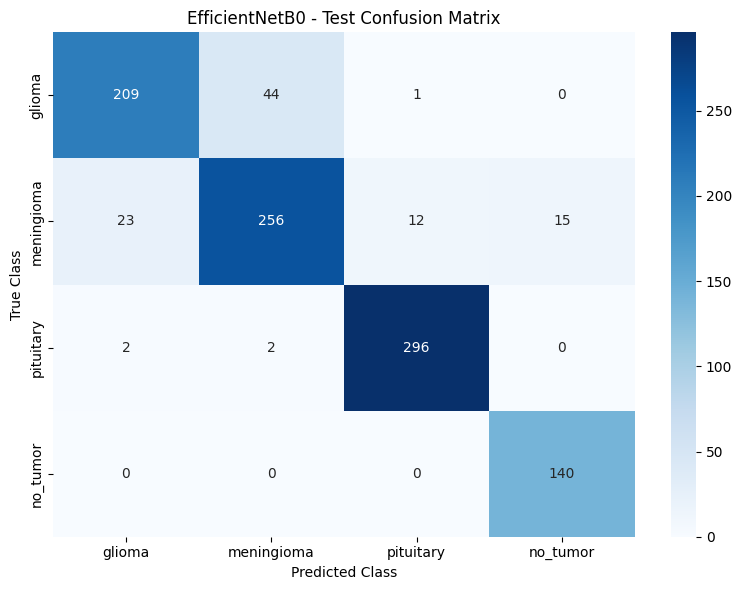

In [44]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Load the best saved model
checkpoint_path = "/kaggle/working/best_efficientnetb0.keras"

efficientnet_model = tf.keras.models.load_model(
    checkpoint_path
)

print("Saved model loaded successfully.")

# Evaluate on the test set
test_loss, test_accuracy = efficientnet_model.evaluate(
    test_ds,
    verbose=1
)

# Collect true labels
y_true = np.concatenate([
    labels.numpy()
    for images, labels in test_ds
])

# Generate predictions
y_prob = efficientnet_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {accuracy_score(y_true, y_pred):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=classes,
    digits=4,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3]
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("EfficientNetB0 - Test Confusion Matrix")
plt.tight_layout()
plt.show()

Found 5000 files belonging to 4 classes.
Using 4000 files for training.
Found 5000 files belonging to 4 classes.
Using 1000 files for validation.
Found 1000 files belonging to 4 classes.
Epoch 1/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step - accuracy: 0.5742 - loss: 0.9910
Epoch 1: val_loss improved from None to 0.38246, saving model to /kaggle/working/efficientnetb3_head.keras

Epoch 1: finished saving model to /kaggle/working/efficientnetb3_head.keras
125/125 ━━━━━━━━━━━━━━━━━━━━ 74s 327ms/step - accuracy: 0.7110 - loss: 0.7331 - val_accuracy: 0.8870 - val_loss: 0.3825
Epoch 2/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - accuracy: 0.8440 - loss: 0.4368
Epoch 2: val_loss improved from 0.38246 to 0.29992, saving model to /kaggle/working/efficientnetb3_head.keras

Epoch 2: finished saving model to /kaggle/working/efficientnetb3_head.keras
125/125 ━━━━━━━━━━━━━━━━━━━━ 21s 164ms/step - accuracy: 0.8468 - loss: 0.4230 - val_accuracy: 0.9130 - val_loss: 0.2999
Epoch 3/5
125/125 ━━━━━━━━━━

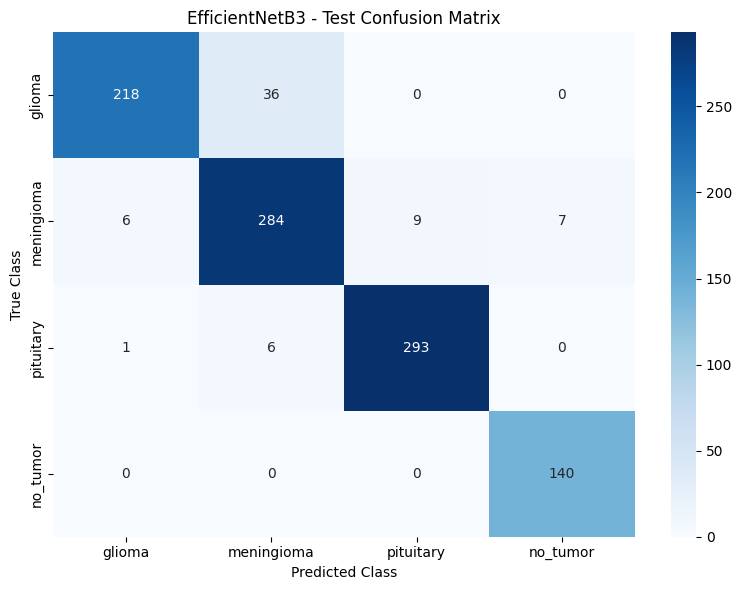

Final model saved: True /kaggle/working/best_efficientnetb3.keras


In [2]:

import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix

# --------------------------------------------------
# 1. Dataset
# --------------------------------------------------
DATASET_DIR = (
    "/kaggle/input/datasets/briscdataset/brisc2025/"
    "brisc2025/classification_task"
)

classes = ["glioma", "meningioma", "pituitary", "no_tumor"]
IMAGE_SIZE = (300, 300)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATASET_DIR, "train"),
    class_names=classes,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATASET_DIR, "train"),
    class_names=classes,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATASET_DIR, "test"),
    class_names=classes,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

# --------------------------------------------------
# 2. Build EfficientNetB3
# --------------------------------------------------
base_model = keras.applications.EfficientNetB3(
    include_top=False,
    weights="imagenet",
    input_shape=(300, 300, 3)
)
base_model.trainable = False

inputs = keras.Input(shape=(300, 300, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(4, activation="softmax")(x)

model = keras.Model(inputs, outputs, name="EfficientNetB3_Finetuned")

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Save separate checkpoints for both stages
head_path = "/kaggle/working/efficientnetb3_head.keras"
fine_path = "/kaggle/working/efficientnetb3_finetuned.keras"

def make_callbacks(path):
    return [
        keras.callbacks.ModelCheckpoint(
            path,
            monitor="val_loss",
            save_best_only=True,
            mode="min",
            verbose=1
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True,
            mode="min",
            verbose=1
        )
    ]

# --------------------------------------------------
# 3. Stage 1: Train classification head
# --------------------------------------------------
history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=make_callbacks(head_path)
)

# --------------------------------------------------
# 4. Stage 2: Fine-tune last 30 layers
# --------------------------------------------------
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen for stability
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=make_callbacks(fine_path)
)

# --------------------------------------------------
# 5. Choose the best stage using validation loss
# --------------------------------------------------
best_head_loss = min(history_head.history["val_loss"])
best_fine_loss = min(history_fine.history["val_loss"])

if best_fine_loss < best_head_loss:
    selected_path = fine_path
    print("Selected: Fine-tuned model")
else:
    selected_path = head_path
    print("Selected: Classification-head model")

model = keras.models.load_model(selected_path)
print("Selected model:", selected_path)

# --------------------------------------------------
# 6. Final test evaluation
# --------------------------------------------------
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

y_true = np.concatenate([y.numpy() for x, y in test_ds])
y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4%}")
print("\nClassification Report:")
print(classification_report(
    y_true, y_pred,
    labels=[0, 1, 2, 3],
    target_names=classes,
    digits=4,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3])

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=classes, yticklabels=classes
)
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("EfficientNetB3 - Test Confusion Matrix")
plt.tight_layout()
plt.show()

# Save the selected model to a single final path
final_path = "/kaggle/working/best_efficientnetb3.keras"
model.save(final_path)
print("Final model saved:", os.path.exists(final_path), final_path)


In [3]:
!pip install -q timm scikit-learn seaborn

In [4]:
import os
import random
import numpy as np
import torch
import torch.nn as nn
import timm

from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("GPU count:", torch.cuda.device_count())

DATA_DIR = (
    "/kaggle/input/datasets/briscdataset/"
    "brisc2025/brisc2025/classification_task"
)

TRAIN_DIR = os.path.join(DATA_DIR, "train")
TEST_DIR = os.path.join(DATA_DIR, "test")

classes = ["glioma", "meningioma", "no_tumor", "pituitary"]
IMG_SIZE = 224
BATCH_SIZE = 32

# Augmentation for training
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomRotation(10),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(
        brightness=0.08,
        contrast=0.08
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# No random augmentation for validation/test
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Separate dataset objects allow different transforms
train_dataset_aug = datasets.ImageFolder(
    TRAIN_DIR, transform=train_transform
)

train_dataset_eval = datasets.ImageFolder(
    TRAIN_DIR, transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    TEST_DIR, transform=eval_transform
)

assert train_dataset_aug.classes == classes, train_dataset_aug.classes
assert test_dataset.classes == classes, test_dataset.classes

targets = np.array(train_dataset_aug.targets)
indices = np.arange(len(targets))

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=SEED,
    stratify=targets
)

train_subset = Subset(train_dataset_aug, train_idx)
val_subset = Subset(train_dataset_eval, val_idx)

train_loader = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training images:", len(train_subset))
print("Validation images:", len(val_subset))
print("Test images:", len(test_dataset))
print("Classes:", train_dataset_aug.classes)

Device: cuda
GPU count: 2
Training images: 4000
Validation images: 1000
Test images: 1000
Classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']


In [5]:
model = timm.create_model(
    "swin_tiny_patch4_window7_224.ms_in1k",
    pretrained=True,
    num_classes=4
)

model = model.to(device)

print(model.get_classifier())
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

Linear(in_features=768, out_features=4, bias=True)
Trainable parameters: 27522430


In [6]:
import copy
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau

criterion = nn.CrossEntropyLoss()

optimizer = AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=0.05
)

scheduler = ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

EPOCHS = 15
PATIENCE = 5

BEST_PATH = "/kaggle/working/best_swin_tiny.pth"

best_val_loss = float("inf")
best_epoch = 0
patience_counter = 0

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))

for epoch in range(EPOCHS):

    # ---------------- Training ----------------
    model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss_sum += loss.item() * labels.size(0)
        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    # ---------------- Validation ----------------
    model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * labels.size(0)
            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4%}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1
        patience_counter = 0

        torch.save(model.state_dict(), BEST_PATH)
        print("  Best model saved.")
    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print("Early stopping.")
        break

print("Best epoch:", best_epoch)
print("Best validation loss:", best_val_loss)
print("Model path:", BEST_PATH)

Epoch 01/15 | Train Loss: 0.3320 | Train Acc: 87.2000% | Val Loss: 0.0959 | Val Acc: 96.8000%
  Best model saved.
Epoch 02/15 | Train Loss: 0.0845 | Train Acc: 97.0250% | Val Loss: 0.0633 | Val Acc: 97.8000%
  Best model saved.
Epoch 03/15 | Train Loss: 0.0639 | Train Acc: 97.8250% | Val Loss: 0.0603 | Val Acc: 98.4000%
  Best model saved.
Epoch 04/15 | Train Loss: 0.0516 | Train Acc: 98.0500% | Val Loss: 0.0493 | Val Acc: 98.5000%
  Best model saved.
Epoch 05/15 | Train Loss: 0.0444 | Train Acc: 98.5500% | Val Loss: 0.0835 | Val Acc: 98.0000%
Epoch 06/15 | Train Loss: 0.0311 | Train Acc: 98.9000% | Val Loss: 0.0800 | Val Acc: 97.7000%
Epoch 07/15 | Train Loss: 0.0213 | Train Acc: 99.3000% | Val Loss: 0.0338 | Val Acc: 98.9000%
  Best model saved.
Epoch 08/15 | Train Loss: 0.0328 | Train Acc: 99.0500% | Val Loss: 0.0391 | Val Acc: 98.8000%
Epoch 09/15 | Train Loss: 0.0236 | Train Acc: 99.1250% | Val Loss: 0.1325 | Val Acc: 95.4000%
Epoch 10/15 | Train Loss: 0.0369 | Train Acc: 98.9500%

Test Loss: 0.0391
Test Accuracy: 99.30%
Correct predictions: 993/1000

Classification Report:
              precision    recall  f1-score   support

      glioma     0.9961    0.9961    0.9961       254
  meningioma     0.9934    0.9837    0.9885       306
    no_tumor     0.9929    1.0000    0.9964       140
   pituitary     0.9901    0.9967    0.9934       300

    accuracy                         0.9930      1000
   macro avg     0.9931    0.9941    0.9936      1000
weighted avg     0.9930    0.9930    0.9930      1000



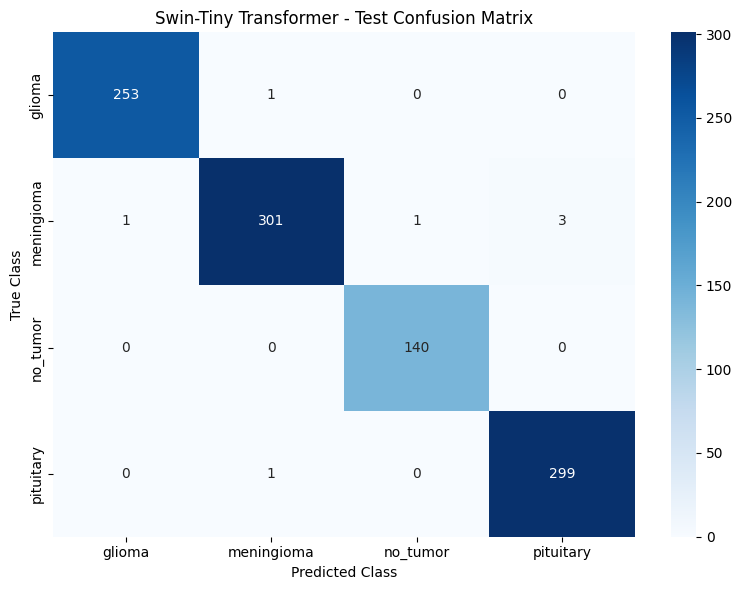

Confusion Matrix:
 [[253   1   0   0]
 [  1 301   1   3]
 [  0   0 140   0]
 [  0   1   0 299]]


In [7]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Load the best model selected by validation loss
model.load_state_dict(
    torch.load(
        "/kaggle/working/best_swin_tiny.pth",
        map_location=device,
        weights_only=True
    )
)
model.eval()

y_true = []
y_pred = []
test_loss_sum = 0.0
test_total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        test_loss_sum += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())
        test_total += labels.size(0)

test_loss = test_loss_sum / test_total
test_accuracy = accuracy_score(y_true, y_pred)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2%}")
print(
    f"Correct predictions: "
    f"{np.sum(np.array(y_true) == np.array(y_pred))}/{test_total}"
)

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=classes,
    digits=4,
    zero_division=0
))

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3]
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Swin-Tiny Transformer - Test Confusion Matrix")
plt.tight_layout()
plt.show()

print("Confusion Matrix:\n", cm)

In [1]:
import os
import copy
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.models import vgg16_bn, VGG16_BN_Weights

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("Number of GPUs:", torch.cuda.device_count())

# Dataset path
DATA_DIR = "/kaggle/input/datasets/briscdataset/brisc2025/brisc2025/classification_task"

TRAIN_DIR = os.path.join(DATA_DIR, "train")
TEST_DIR = os.path.join(DATA_DIR, "test")

# Hyperparameters
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 15
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 0.05

NUM_CLASSES = 4

print("Configuration loaded successfully.")

Device: cuda
Number of GPUs: 2
Configuration loaded successfully.


In [8]:
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomRotation(10),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(
        brightness=0.08,
        contrast=0.08
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [9]:
train_dataset = datasets.ImageFolder(
    TRAIN_DIR,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    TRAIN_DIR,
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    TEST_DIR,
    transform=eval_transform
)

classes = train_dataset.classes

print("Classes:", classes)
print("Total Training Images:", len(train_dataset))
print("Total Test Images:", len(test_dataset))

indices = np.arange(len(train_dataset))

train_indices, val_indices = train_test_split(
    indices,
    test_size=0.20,
    random_state=SEED,
    stratify=train_dataset.targets
)

train_subset = Subset(train_dataset, train_indices)
val_subset = Subset(val_dataset, val_indices)

train_loader = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training samples:", len(train_subset))
print("Validation samples:", len(val_subset))
print("Testing samples:", len(test_dataset))

Classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']
Total Training Images: 5000
Total Test Images: 1000
Training samples: 4000
Validation samples: 1000
Testing samples: 1000


In [10]:
weights = VGG16_BN_Weights.DEFAULT

model = vgg16_bn(weights=weights)

# Replace final classification layer
in_features = model.classifier[6].in_features

model.classifier[6] = nn.Linear(
    in_features,
    NUM_CLASSES
)

model = model.to(device)

# Multi-GPU support
if torch.cuda.device_count() > 1:
    model = nn.DataParallel(model)

print(model)

Downloading: "https://download.pytorch.org/models/vgg16_bn-6c64b313.pth" to /root/.cache/torch/hub/checkpoints/vgg16_bn-6c64b313.pth


100%|██████████| 528M/528M [00:02<00:00, 208MB/s]  


DataParallel(
  (module): VGG(
    (features): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (7): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (8): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (9): ReLU(inplace=True)
      (10): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (11): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (12): ReLU(inplace=True)
      (13): MaxPool2d(kernel_size=2, stride=2, padding=0

In [14]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

In [17]:
def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc


def evaluate(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return (
        epoch_loss,
        epoch_acc,
        all_predictions,
        all_labels
    )

In [18]:
best_val_loss = float("inf")
best_val_acc = 0.0

best_model_weights = copy.deepcopy(model.state_dict())

patience = 5
counter = 0

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc, _, _ = evaluate(
        model,
        val_loader,
        criterion,
        device
    )

    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)

    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_acc:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_val_acc = val_acc

        best_model_weights = copy.deepcopy(
            model.state_dict()
        )

        torch.save(
            best_model_weights,
            "/kaggle/working/best_vgg16_bn.pth"
        )

        counter = 0

        print("Best model saved.")

    else:

        counter += 1

        print(f"Early stopping counter: {counter}/{patience}")

    if counter >= patience:

        print("Early stopping triggered.")
        break

model.load_state_dict(best_model_weights)

print("\nTraining completed.")
print("Best Validation Loss:", best_val_loss)
print("Validation Accuracy at Best Loss:", best_val_acc)

Epoch [1/15] Train Loss: 0.3153 Train Acc: 0.8812 Val Loss: 0.1867 Val Acc: 0.9490
Best model saved.
Epoch [2/15] Train Loss: 0.1153 Train Acc: 0.9607 Val Loss: 0.1181 Val Acc: 0.9670
Best model saved.
Epoch [3/15] Train Loss: 0.0787 Train Acc: 0.9730 Val Loss: 0.0658 Val Acc: 0.9830
Best model saved.
Epoch [4/15] Train Loss: 0.0612 Train Acc: 0.9820 Val Loss: 0.2190 Val Acc: 0.9170
Early stopping counter: 1/5
Epoch [5/15] Train Loss: 0.0394 Train Acc: 0.9880 Val Loss: 0.0882 Val Acc: 0.9810
Early stopping counter: 2/5
Epoch [6/15] Train Loss: 0.0401 Train Acc: 0.9888 Val Loss: 0.0832 Val Acc: 0.9770
Early stopping counter: 3/5
Epoch [7/15] Train Loss: 0.0208 Train Acc: 0.9925 Val Loss: 0.0653 Val Acc: 0.9830
Best model saved.
Epoch [8/15] Train Loss: 0.0108 Train Acc: 0.9970 Val Loss: 0.0503 Val Acc: 0.9890
Best model saved.
Epoch [9/15] Train Loss: 0.0101 Train Acc: 0.9968 Val Loss: 0.0870 Val Acc: 0.9840
Early stopping counter: 1/5
Epoch [10/15] Train Loss: 0.0091 Train Acc: 0.9972 

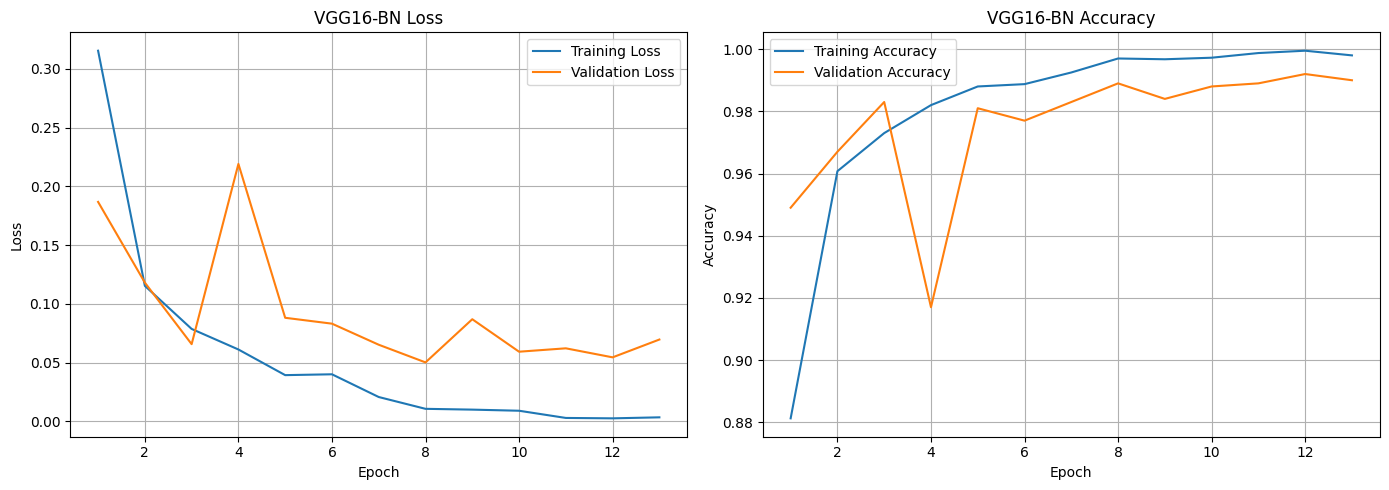

In [19]:
epochs_range = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)

plt.plot(
    epochs_range,
    history["train_loss"],
    label="Training Loss"
)

plt.plot(
    epochs_range,
    history["val_loss"],
    label="Validation Loss"
)

plt.title("VGG16-BN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)

plt.plot(
    epochs_range,
    history["train_acc"],
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    history["val_acc"],
    label="Validation Accuracy"
)

plt.title("VGG16-BN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [20]:
model.load_state_dict(
    torch.load(
        "/kaggle/working/best_vgg16_bn.pth",
        map_location=device,
        weights_only=True
    )
)

test_loss, test_acc, y_pred, y_true = evaluate(
    model,
    test_loader,
    criterion,
    device
)

print("=" * 50)
print("VGG16-BN FINAL TEST RESULTS")
print("=" * 50)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc * 100:.2f}%")

print("\nClassification Report:\n")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=classes,
        digits=4
    )
)

print(
    "Macro F1-Score:",
    f1_score(y_true, y_pred, average="macro")
)

VGG16-BN FINAL TEST RESULTS
Test Loss: 0.0571
Test Accuracy: 98.90%

Classification Report:

              precision    recall  f1-score   support

      glioma     0.9921    0.9882    0.9901       254
  meningioma     0.9868    0.9771    0.9819       306
    no_tumor     0.9790    1.0000    0.9894       140
   pituitary     0.9934    0.9967    0.9950       300

    accuracy                         0.9890      1000
   macro avg     0.9878    0.9905    0.9891      1000
weighted avg     0.9890    0.9890    0.9890      1000

Macro F1-Score: 0.9891208206105437


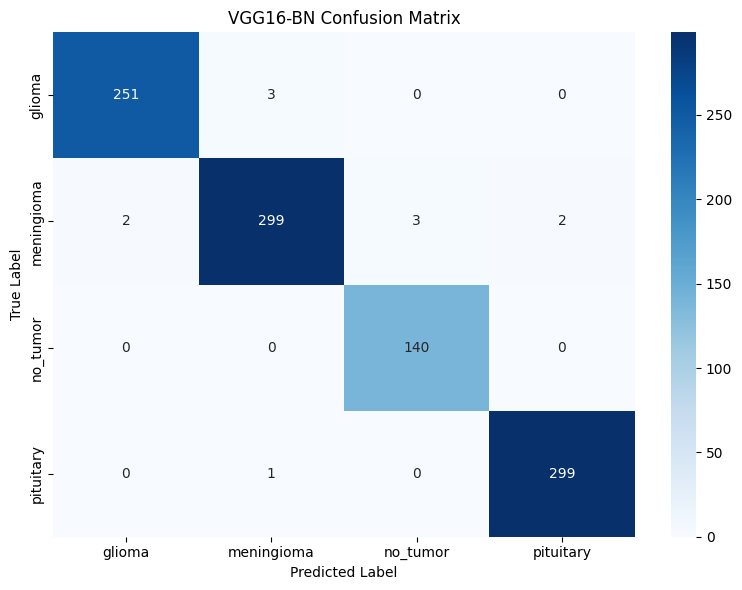

In [21]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.title("VGG16-BN Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()
plt.show()